# 02 - Dynamic-range truncation and inverse mapping (Sec. VI)
Deterministic computations: continuous map F(kappa; DR), its inverse, and the discrete-grid error.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from channel_model import *
P = load_channel_parameters()

In [2]:
from channel_model.dynamic_range import continuous_observables, discrete_observables, AngleGrid, regime_boundaries_db
dr = np.arange(1, 51.)
o = continuous_observables(10.0, 0.3*np.pi, 0.2*np.pi, dr)
print('regime boundaries [dB]:', np.round(regime_boundaries_db(0.3*np.pi, 0.2*np.pi), 2))
inv = invert_spreads(np.column_stack([o['s_tau'], o['s_r'], o['s_t']]), dr)
print('max relative kappa error:', np.abs(inv.kappa / [10, 0.3*np.pi, 0.2*np.pi] - 1).max())

regime boundaries [dB]: [14.48 21.71 36.19]


max relative kappa error: 5.921696466515414e-11


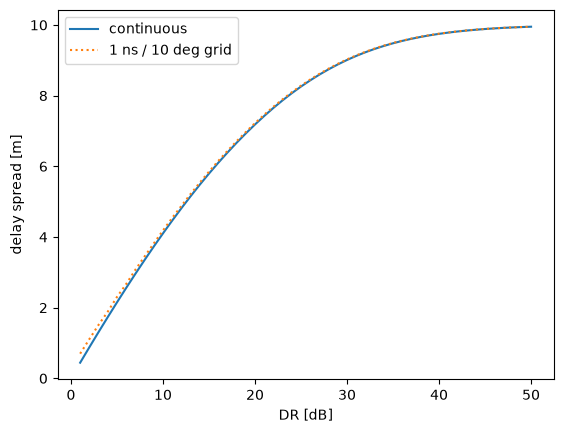

In [3]:
g = discrete_observables(10/0.29979, 0.3*np.pi, 0.2*np.pi, dr, AngleGrid(10.), 0.29979)
plt.plot(dr, o['s_tau'], label='continuous'); plt.plot(dr, g['s_tau'], ':', label='1 ns / 10 deg grid')
plt.xlabel('DR [dB]'); plt.ylabel('delay spread [m]'); plt.legend(); plt.show()